In [0]:
import boto3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [0]:
# Set plotting style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Load data from S3 

print("Loading data from S3...")
df = pd.read_parquet("s3://finsight-bank-data/gold/ml_features/")

Loading data from S3...


In [0]:
df.head()

,customer_id,age,gender,education,marital_status,occupation,annual_income,credit_score,customer_since,ingestion_timestamp,source_system,pipeline_version,total_spending,transaction_count,active_account_count,average_transaction_amount,spending_per_transaction,first_transaction_timestamp,last_transaction_timestamp,first_transaction_date,last_transaction_date,transaction_observation_span_days,transaction_frequency_per_month,transaction_activity_flag,high_average_transaction_flag,days_since_last_transaction,customer_activity_status,spending_per_active_account,transactions_per_active_account,spending_segment,feature_as_of_date,gold_created_timestamp
0,1000030,38,Female,Master,Married,Finance,60968.04,580,2022-11-26,2026-09-16 13:39:20.126914,synthetic_banking_transactions,1.1,0.00,0,0,0.00,0.00,NaT,NaT,None,None,0,0.000000,0,0,NaN,NO_ACTIVITY,0.00,0.0,NO_SPEND,2025-12-30,2026-09-23 11:26:51.601503
1,1000059,46,Male,Bachelor,Single,Education,51248.15,601,2019-05-04,2026-09-16 13:39:20.126914,synthetic_banking_transactions,1.1,0.00,0,0,0.00,0.00,NaT,NaT,None,None,0,0.000000,0,0,NaN,NO_ACTIVITY,0.00,0.0,NO_SPEND,2025-12-30,2026-09-23 11:26:51.601503
2,1000078,38,Male,Master,Divorced,Technology,60194.40,559,2020-12-09,2026-09-16 13:39:20.126914,synthetic_banking_transactions,1.1,189.14,6,1,31.52,31.52,2023-01-01 06:58:29,2025-08-12 22:00:41,2023-01-01,2025-08-12,954,0.191447,1,0,140.0,INACTIVE,189.14,6.0,LOW,2025-12-30,2026-09-23 11:26:51.601503
3,1000085,31,Male,Master,Single,Public Sector,60636.90,548,2014-11-07,2026-09-16 13:39:20.126914,synthetic_banking_transactions,1.1,0.00,0,0,0.00,0.00,NaT,NaT,None,None,0,0.000000,0,0,NaN,NO_ACTIVITY,0.00,0.0,NO_SPEND,2025-12-30,2026-09-23 11:26:51.601503
4,1000106,47,Male,Bachelor,Single,Finance,63564.53,577,2020-11-17,2026-09-16 13:39:20.126914,synthetic_banking_transactions,1.1,4106.19,17,1,241.54,241.54,2023-01-16 16:13:07,2025-12-30 08:07:18,2023-01-16,2025-12-30,1079,0.479592,1,0,0.0,ACTIVE,4106.19,17.0,MEDIUM,2025-12-30,2026-09-23 11:26:51.601503


In [0]:
ml_df = df.copy()
money_features = [
    "annual_income",
    "total_spending",
    "average_transaction_amount",
    "spending_per_transaction"
]
# Safely convert only columns that exist in the dataframe
existing_money_features = [col for col in money_features if col in ml_df.columns]
for col in existing_money_features:
    ml_df[col] = pd.to_numeric(ml_df[col], errors="coerce")
ml_df[existing_money_features] = ml_df[existing_money_features].fillna(0)

In [0]:
cluster_features = [
    "age",
    "annual_income",
    "credit_score",
    "total_spending",
    "transaction_count",
    "average_transaction_amount",
    "transaction_observation_span_days",
    "transaction_frequency_per_month",
    "spending_per_active_account",
    "transactions_per_active_account"
]

In [0]:
ml_df.head()

,customer_id,age,gender,education,marital_status,occupation,annual_income,credit_score,customer_since,ingestion_timestamp,source_system,pipeline_version,total_spending,transaction_count,active_account_count,average_transaction_amount,spending_per_transaction,first_transaction_timestamp,last_transaction_timestamp,first_transaction_date,last_transaction_date,transaction_observation_span_days,transaction_frequency_per_month,transaction_activity_flag,high_average_transaction_flag,days_since_last_transaction,customer_activity_status,spending_per_active_account,transactions_per_active_account,spending_segment,feature_as_of_date,gold_created_timestamp
0,1000030,38,Female,Master,Married,Finance,60968.04,580,2022-11-26,2026-09-16 13:39:20.126914,synthetic_banking_transactions,1.1,0.00,0,0,0.00,0.00,NaT,NaT,None,None,0,0.000000,0,0,NaN,NO_ACTIVITY,0.00,0.0,NO_SPEND,2025-12-30,2026-09-23 11:26:51.601503
1,1000059,46,Male,Bachelor,Single,Education,51248.15,601,2019-05-04,2026-09-16 13:39:20.126914,synthetic_banking_transactions,1.1,0.00,0,0,0.00,0.00,NaT,NaT,None,None,0,0.000000,0,0,NaN,NO_ACTIVITY,0.00,0.0,NO_SPEND,2025-12-30,2026-09-23 11:26:51.601503
2,1000078,38,Male,Master,Divorced,Technology,60194.40,559,2020-12-09,2026-09-16 13:39:20.126914,synthetic_banking_transactions,1.1,189.14,6,1,31.52,31.52,2023-01-01 06:58:29,2025-08-12 22:00:41,2023-01-01,2025-08-12,954,0.191447,1,0,140.0,INACTIVE,189.14,6.0,LOW,2025-12-30,2026-09-23 11:26:51.601503
3,1000085,31,Male,Master,Single,Public Sector,60636.90,548,2014-11-07,2026-09-16 13:39:20.126914,synthetic_banking_transactions,1.1,0.00,0,0,0.00,0.00,NaT,NaT,None,None,0,0.000000,0,0,NaN,NO_ACTIVITY,0.00,0.0,NO_SPEND,2025-12-30,2026-09-23 11:26:51.601503
4,1000106,47,Male,Bachelor,Single,Finance,63564.53,577,2020-11-17,2026-09-16 13:39:20.126914,synthetic_banking_transactions,1.1,4106.19,17,1,241.54,241.54,2023-01-16 16:13:07,2025-12-30 08:07:18,2023-01-16,2025-12-30,1079,0.479592,1,0,0.0,ACTIVE,4106.19,17.0,MEDIUM,2025-12-30,2026-09-23 11:26:51.601503


In [0]:
missing_features = [col for col in cluster_features if col not in ml_df.columns]
if missing_features:
    raise ValueError(f"The following required cluster features are missing from the dataframe: {missing_features}")

X = ml_df[cluster_features].copy()
X = X.fillna(0)

In [0]:
#feature scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print(f"Scaled feature matrix shape: {X_scaled.shape}")

Scaled feature matrix shape: (99900, 10)


In [0]:
#kmeans
inertias = []
silhouette_scores = []
k_values = range(2, 9)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    inertias.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

In [0]:
print("\nInertias per K:")
for k, inertia in zip(k_values, inertias):
    print(f"K={k}: {inertia:,.2f}")


Inertias per K:
K=2: 636,940.45
K=3: 513,454.72
K=4: 448,801.77
K=5: 392,292.35
K=6: 365,839.66
K=7: 342,722.86
K=8: 324,336.39


In [0]:
print("\nSilhouette Scores per K:")
for k, score in zip(k_values, silhouette_scores):
    print(f"K={k}: {score:.4f}")


Silhouette Scores per K:
K=2: 0.3624
K=3: 0.2673
K=4: 0.2500
K=5: 0.2610
K=6: 0.2178
K=7: 0.1975
K=8: 0.1912


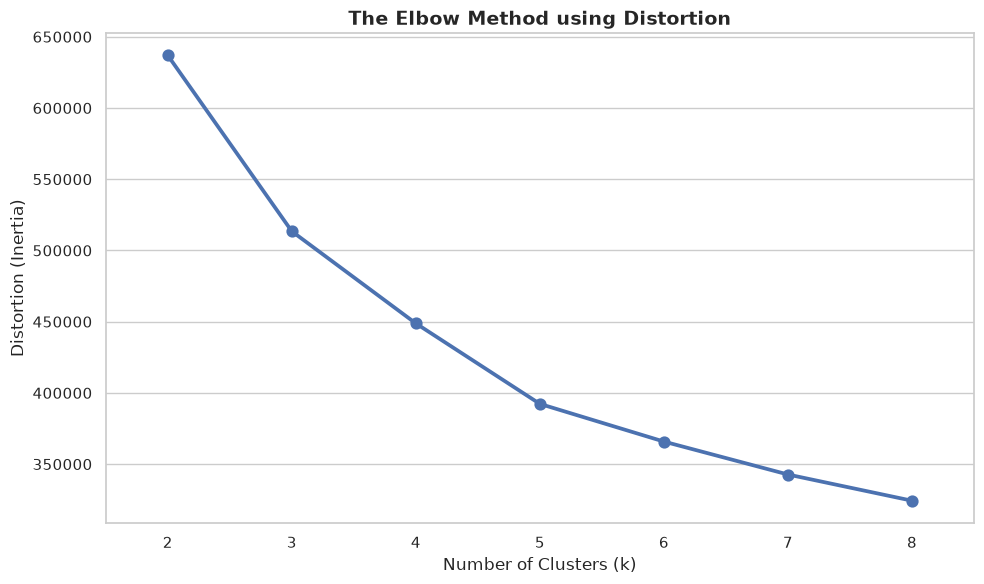

In [0]:
# elbow graph
plt.figure(figsize=(10, 6))
sns.pointplot(x=list(k_values), y=list(inertias), color="b", markers="o", linestyles="-")
plt.xlabel('Number of Clusters (k)', fontsize=12)
plt.ylabel('Distortion (Inertia)', fontsize=12)
plt.title('The Elbow Method using Distortion', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [0]:
optimal_k = 3
print(f"\nFitting final K-Means model with K={optimal_k}...")
kmeans_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
final_labels = kmeans_final.fit_predict(X_scaled)
ml_df["cluster"] = final_labels


Fitting final K-Means model with K=3...


In [0]:
cluster_summary = ml_df.groupby("cluster")[cluster_features].mean().round(2)
print("\nCluster Profiles (Mean Values):")
display(cluster_summary)


Cluster Profiles (Mean Values):


,age,annual_income,credit_score,total_spending,transaction_count,average_transaction_amount,transaction_observation_span_days,transaction_frequency_per_month,spending_per_active_account,transactions_per_active_account
cluster,,,,,,,,,,
0,41.91,59941.10,557.41,13739.62,35.51,441.35,1018.07,1.05,6148.94,14.20
1,41.64,59609.08,556.09,2.96,0.05,0.60,5.31,0.00,2.95,0.05
2,41.58,59668.36,556.47,3841.01,18.90,214.97,963.08,0.59,2676.81,12.75


In [0]:
# 9. Map Segment Names First
segment_name_map = {
    0: "High Activity / High Spending",
    1: "Inactive / Low Activity",
    2: "Moderate Activity / Spending",
}

# Create a text column so Seaborn automatically manages colors and legend mapping
ml_df["segment_name"] = ml_df["cluster"].map(segment_name_map)

# 8. Visualize Clusters (Scatter Plot)
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=ml_df,
    x="transaction_count",
    y="total_spending",
    hue="segment_name",  # Use the named column here!
    palette="Set1",
    alpha=0.6,
    s=50,
)

plt.title(
    "Customer Segments: Transaction Count vs. Total Spending",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Transaction Count", fontsize=12)
plt.ylabel("Total Spending ($)", fontsize=12)

# No manual labels needed; Seaborn links the colors and text automatically now
plt.legend(title="Cluster", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.tight_layout()
plt.show()

# Prepare final output dataframe
customer_segments = ml_df[["customer_id", "cluster", "segment_name"]].copy()

In [0]:


# 10. Save to S3 Parquet
output_path = "s3://finsight-bank-data/gold/ml_features/customer_segments/customer_segments.parquet"
customer_segments.to_parquet(output_path, index=False)
print(f"\nSuccess! Customer segments successfully saved to: {output_path}")